读取 `data/72/dat` 的速度和压力快照，对速度扰动做 exact DMD，再用 u、v、p 联合 DMD 提取 p' 模态，结果保存到 `results/72/DMD`。

In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import matplotlib.tri as mtri
from matplotlib.path import Path as MplPath
from scipy.spatial import cKDTree

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'stix',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 10,
    'figure.dpi': 140,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
})

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists() and (p / 'data').is_dir())
CASE_DIR = REPO_ROOT / 'data' / '72' / 'dat'
OUT_DIR = REPO_ROOT / 'results' / '72' / 'DMD'
OUT_DIR.mkdir(parents=True, exist_ok=True)
DMD_RANK = 40
N_PLOT = 4

print(f'repository: {REPO_ROOT}')
print(f'case      : {CASE_DIR}')
print(f'output    : {OUT_DIR}')

repository: C:\Users\Administrator\Desktop\PurineCFD-Plugin
case      : C:\Users\Administrator\Desktop\PurineCFD-Plugin\data\72\dat
output    : C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\DMD


每个快照读取 `u、v、p`，减去各自时间平均值；时间由 `history.csv` 匹配。

In [2]:
def step_number(path):
    return int(path.stem.split('_')[1])

snapshot_files = sorted(CASE_DIR.glob('step_*.dat'), key=step_number)
first = np.loadtxt(snapshot_files[0], skiprows=2, usecols=(0, 1, 3, 4, 6))
x = first[:, 0]
y = first[:, 1]
n_snapshots = len(snapshot_files)
n_nodes = first.shape[0]
velocity = np.empty((n_snapshots, n_nodes, 2), dtype=np.float64)
pressure = np.empty((n_snapshots, n_nodes), dtype=np.float64)
velocity[0] = first[:, 2:4]
pressure[0] = first[:, 4]

for i, path in enumerate(snapshot_files[1:], start=1):
    current = np.loadtxt(path, skiprows=2, usecols=(0, 1, 3, 4, 6))
    if current.shape != first.shape:
        raise ValueError(f'incompatible shape in {path}: {current.shape}')
    if not np.allclose(current[:, :2], first[:, :2], rtol=0.0, atol=1e-12):
        raise ValueError(f'coordinates changed in {path}')
    velocity[i] = current[:, 2:4]
    pressure[i] = current[:, 4]

history = pd.read_csv(CASE_DIR / 'history.csv')
steps = np.array([step_number(path) for path in snapshot_files], dtype=int)
time = np.interp(steps, history['step'].to_numpy(), history['time'].to_numpy())
dt = float(np.median(np.diff(time)))
mean_velocity = velocity.mean(axis=0)
mean_pressure = pressure.mean(axis=0)
fluctuation = velocity - mean_velocity
pressure_fluctuation = pressure - mean_pressure
X = np.vstack((fluctuation[:-1, :, 0].T, fluctuation[:-1, :, 1].T))
Y = np.vstack((fluctuation[1:, :, 0].T, fluctuation[1:, :, 1].T))

print(f'nodes     : {n_nodes}')
print(f'snapshots : {n_snapshots}')
print(f'time      : {time[0]:.6f} ... {time[-1]:.6f} s')
print(f'dt        : {dt:.6e} s')
print(f'state     : {X.shape[0]} x {X.shape[1]}')

nodes     : 62591
snapshots : 166
time      : 0.150300 ... 0.199800 s
dt        : 3.000000e-04 s
state     : 125182 x 165


对 X1 做截断 SVD，构造低维传播算子并恢复 exact DMD 模态。频率和增长率由 omega = log(mu)/dt 得到。

In [3]:
U, singular_values, Vh = np.linalg.svd(X, full_matrices=False)
rank = min(DMD_RANK, singular_values.size)
Ur = U[:, :rank]
Sr = singular_values[:rank]
Vr = Vh.conj().T[:, :rank]
A_tilde = Ur.conj().T @ Y @ Vr / Sr[None, :]
eigenvalues, eigenvectors = np.linalg.eig(A_tilde)
modes = Y @ Vr / Sr[None, :] @ eigenvectors
omega = np.log(eigenvalues.astype(np.complex128)) / dt
initial_state = X[:, 0]
amplitudes = np.linalg.lstsq(modes, initial_state, rcond=None)[0]
mode_amplitude = np.abs(amplitudes)
frequency = omega.imag / (2.0 * np.pi)
growth_rate = omega.real
mode_order = np.argsort(mode_amplitude)[::-1]

reconstruction = modes @ (amplitudes[:, None] * np.exp(omega[:, None] * (time[:-1] - time[0])))
relative_error = np.linalg.norm(X - reconstruction.real, axis=0) / np.linalg.norm(X, axis=0)
summary = pd.DataFrame({
    'mode': np.arange(1, rank + 1),
    'eigenvalue_real': eigenvalues.real,
    'eigenvalue_imag': eigenvalues.imag,
    'frequency_hz': frequency,
    'growth_rate_1_s': growth_rate,
    'growth_rate_1_ms': growth_rate * 1e-3,
    'amplitude': mode_amplitude,
    'amplitude_rank': np.empty(rank, dtype=int),
})
summary.loc[mode_order, 'amplitude_rank'] = np.arange(1, rank + 1)
summary = summary.sort_values('amplitude_rank').reset_index(drop=True)

print(f'rank      : {rank}')
print(f'mean reconstruction error: {relative_error.mean():.6e}')
print(f'max reconstruction error : {relative_error.max():.6e}')
print(summary.head(10).to_string(index=False, float_format=lambda value: f'{value:.6e}'))

rank      : 40
mean reconstruction error: 4.946217e-01
max reconstruction error : 1.293315e+00
 mode  eigenvalue_real  eigenvalue_imag  frequency_hz  growth_rate_1_s  growth_rate_1_ms    amplitude  amplitude_rank
   34     9.962467e-01     3.761108e-02  2.001896e+01    -1.016085e+01     -1.016085e-02 2.898138e+03               1
   35     9.962467e-01    -3.761108e-02 -2.001896e+01    -1.016085e+01     -1.016085e-02 2.898138e+03               2
   36     9.826863e-01     6.570575e-02  3.541942e+01    -5.078335e+01     -5.078335e-02 1.717811e+03               3
   37     9.826863e-01    -6.570575e-02 -3.541942e+01    -5.078335e+01     -5.078335e-02 1.717811e+03               4
   33     9.944338e-01    -1.096143e-01 -5.824255e+01     1.522515e+00      1.522515e-03 1.194809e+03               5
   32     9.944338e-01     1.096143e-01  5.824255e+01     1.522515e+00      1.522515e-03 1.194809e+03               6
   25     9.065867e-01    -2.726692e-01 -1.549947e+02    -1.825636e+02     -1.8

C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\DMD\dmd_eigenvalues.png
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\DMD\dmd_frequency_growth.png


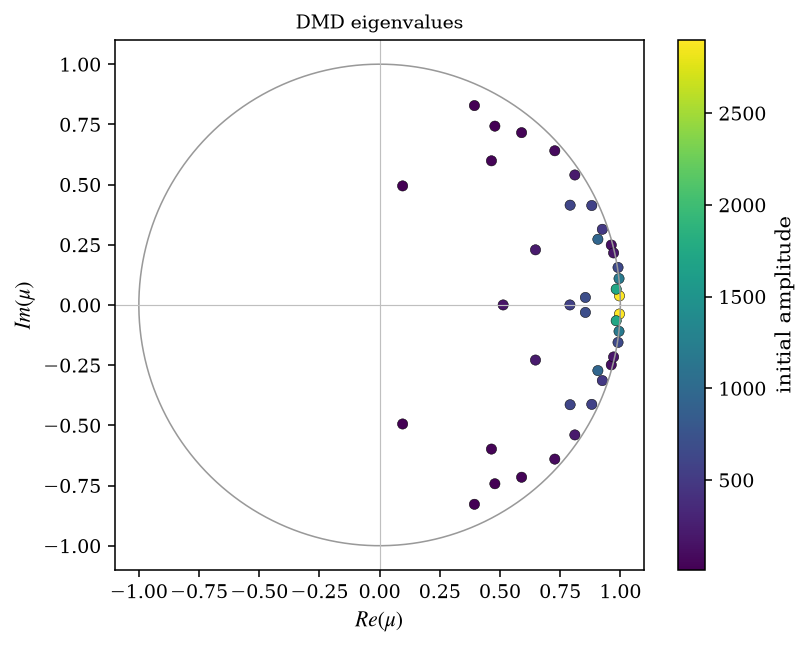

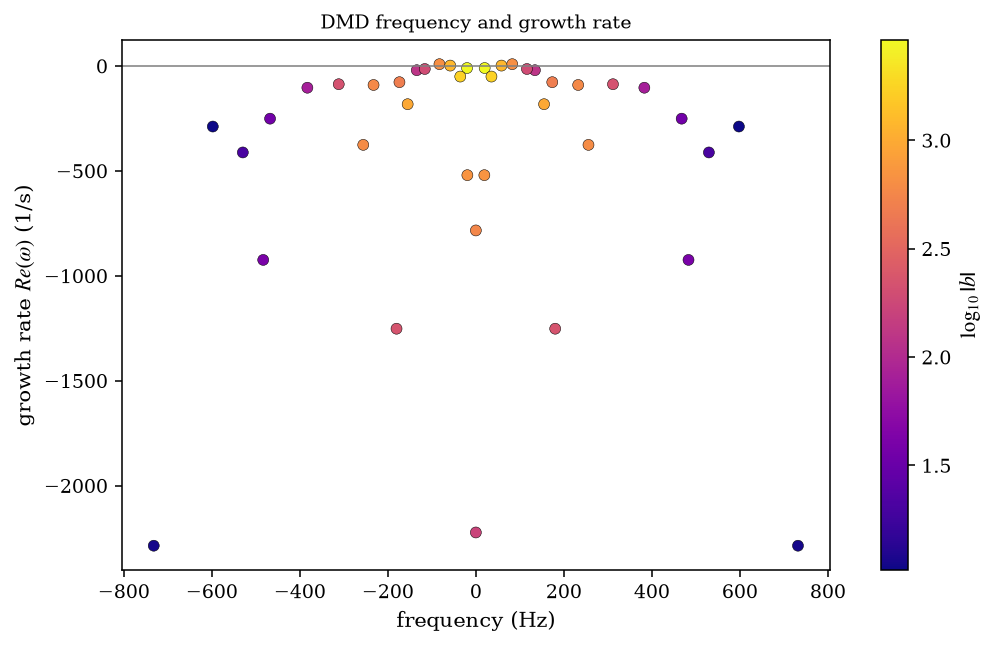

In [4]:
fig, ax = plt.subplots(figsize=(6.0, 4.5), layout='constrained')
theta = np.linspace(0.0, 2.0 * np.pi, 400)
ax.plot(np.cos(theta), np.sin(theta), color='0.6', linewidth=0.8)
scatter = ax.scatter(eigenvalues.real, eigenvalues.imag, c=mode_amplitude, cmap='viridis', s=28, edgecolors='k', linewidths=0.25)
ax.axhline(0.0, color='0.75', linewidth=0.6)
ax.axvline(0.0, color='0.75', linewidth=0.6)
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel(r'$Re(\mu)$')
ax.set_ylabel(r'$Im(\mu)$')
ax.set_title('DMD eigenvalues')
fig.colorbar(scatter, ax=ax, label='initial amplitude')
fig.savefig(OUT_DIR / 'dmd_eigenvalues.png')
plt.show()

fig, ax = plt.subplots(figsize=(7.0, 4.5), layout='constrained')
valid = np.isfinite(frequency) & np.isfinite(growth_rate) & (mode_amplitude > 0.0)
scatter = ax.scatter(frequency[valid], growth_rate[valid], c=np.log10(mode_amplitude[valid]), cmap='plasma', s=32, edgecolors='k', linewidths=0.25)
ax.axhline(0.0, color='0.5', linewidth=0.8)
ax.set_xlabel('frequency (Hz)')
ax.set_ylabel(r'growth rate $Re(\omega)$ (1/s)')
ax.set_title('DMD frequency and growth rate')
fig.colorbar(scatter, ax=ax, label=r'$\log_{10}|b|$')
fig.savefig(OUT_DIR / 'dmd_frequency_growth.png')
plt.show()
print(OUT_DIR / 'dmd_eigenvalues.png')
print(OUT_DIR / 'dmd_frequency_growth.png')

模态云图直接使用 `mesh.txt` 中的 `wall` 边界。绘图区集中在翼型及尾迹附近，翼型内部三角形被遮罩。

wall edges: 474, wall nodes: 474, chord: 0.230611
local triangles: 77818, masked: 23296
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\DMD\dmd_modes_1_4.png


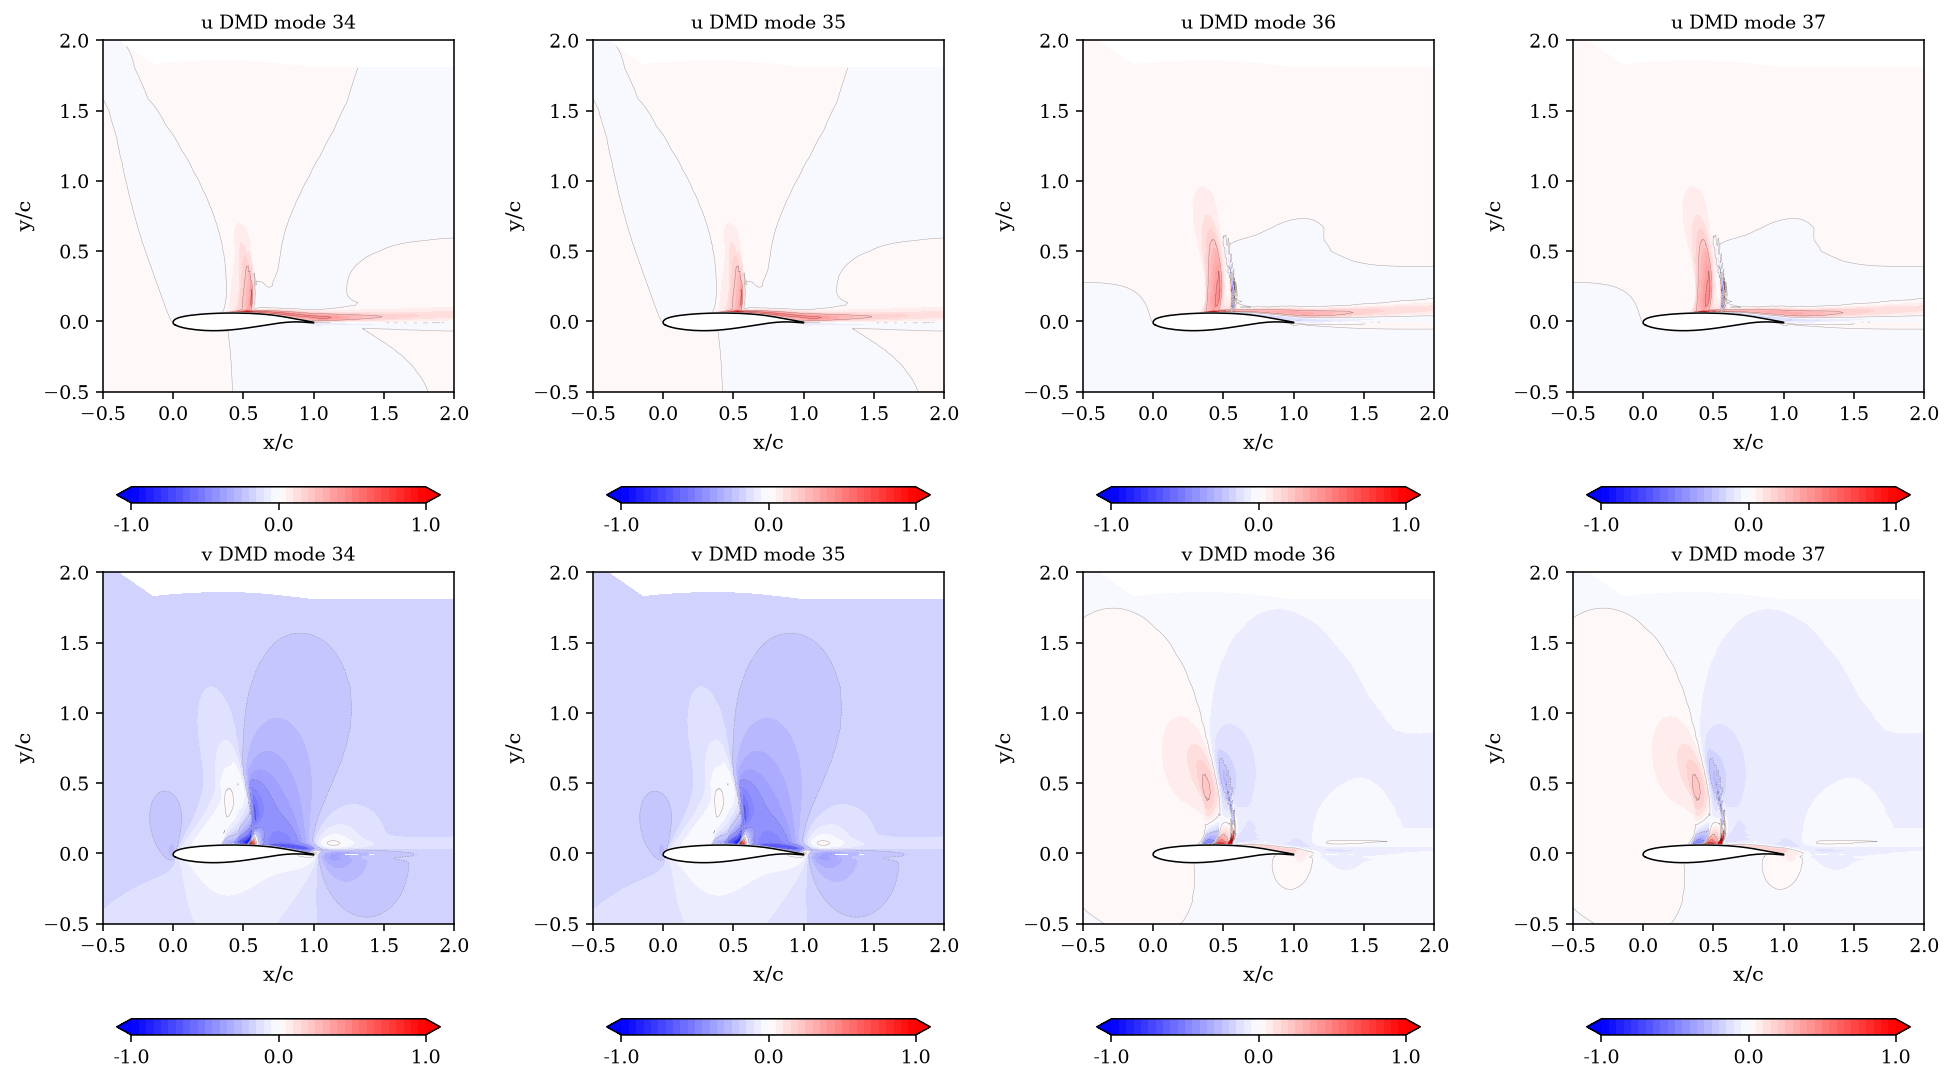

In [5]:
mesh_lines = (CASE_DIR / 'mesh.txt').read_text(encoding='utf-8').splitlines()
mesh_node_count = int(mesh_lines[0].split()[2])
mesh_nodes = np.asarray([[float(parts[1]), float(parts[2])] for parts in (line.split() for line in mesh_lines[5:5 + mesh_node_count])])
wall_start = mesh_lines.index('wall')
wall_end = mesh_lines.index('(end)', wall_start)
wall_edges = np.asarray([[int(parts[1]) - 1, int(parts[2]) - 1] for parts in (line.split() for line in mesh_lines[wall_start + 1:wall_end]) if len(parts) >= 4])
wall_neighbours = {}
for first_node, second_node in wall_edges:
    wall_neighbours.setdefault(first_node, []).append(second_node)
    wall_neighbours.setdefault(second_node, []).append(first_node)
wall_start_node = min(wall_neighbours)
wall_order = [wall_start_node]
previous_node = None
current_node = wall_start_node
while True:
    candidates = wall_neighbours[current_node]
    next_node = candidates[0] if candidates[0] != previous_node else candidates[1]
    if next_node == wall_start_node:
        break
    wall_order.append(next_node)
    previous_node, current_node = current_node, next_node
wall_mesh = mesh_nodes[np.asarray(wall_order)]
wall_data_indices = cKDTree(np.column_stack((x, y))).query(wall_mesh, k=1)[1]
wall = np.column_stack((x[wall_data_indices], y[wall_data_indices]))
x_le = wall[:, 0].min()
y_center = wall[:, 1].mean()
chord = wall[:, 0].max() - x_le
x_norm = (x - x_le) / chord
y_norm = (y - y_center) / chord
body = np.column_stack(((wall[:, 0] - x_le) / chord, (wall[:, 1] - y_center) / chord))
body_path = MplPath(body, closed=True)
x_plot = (-0.5, 2.0)
y_plot = (-0.5, 2.0)
near = (x_norm >= x_plot[0] - 0.05) & (x_norm <= x_plot[1] + 0.05) & (y_norm >= y_plot[0] - 0.05) & (y_norm <= y_plot[1] + 0.05)
tri = mtri.Triangulation(x_norm[near], y_norm[near])
tri_mask = mtri.TriAnalyzer(tri).get_flat_tri_mask(min_circle_ratio=0.01, rescale=True)
triangle_centers = np.column_stack((x_norm[near][tri.triangles].mean(axis=1), y_norm[near][tri.triangles].mean(axis=1)))
tri_mask |= body_path.contains_points(triangle_centers)
tri.set_mask(tri_mask)

def plot_mode(ax, values, title):
    local_values = np.real(values[near])
    scale = np.max(np.abs(local_values))
    local_values = local_values / scale if scale else local_values
    levels = np.linspace(-1.0, 1.0, 41)
    image = ax.tricontourf(tri, local_values, levels=levels, cmap='bwr', extend='both')
    ax.tricontour(tri, local_values, levels=levels[::4], colors='k', linewidths=0.25, alpha=0.35)
    ax.fill(body[:, 0], body[:, 1], color='white', zorder=3)
    ax.plot(body[:, 0], body[:, 1], color='k', linewidth=0.8, zorder=4)
    ax.set_xlim(*x_plot)
    ax.set_ylim(*y_plot)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title)
    ax.set_xlabel('x/c')
    ax.set_ylabel('y/c')
    return image

plot_modes = mode_order[:min(N_PLOT, rank)]
fig, axes = plt.subplots(2, len(plot_modes), figsize=(3.5 * len(plot_modes), 7.6), squeeze=False, layout='constrained')
for column, mode_index in enumerate(plot_modes):
    mode_number = mode_index + 1
    image_u = plot_mode(axes[0, column], modes[:n_nodes, mode_index], f'u DMD mode {mode_number}')
    image_v = plot_mode(axes[1, column], modes[n_nodes:, mode_index], f'v DMD mode {mode_number}')
    fig.colorbar(image_u, ax=axes[0, column], orientation='horizontal', pad=0.08, shrink=0.8, ticks=(-1.0, 0.0, 1.0), format='%.1f')
    fig.colorbar(image_v, ax=axes[1, column], orientation='horizontal', pad=0.08, shrink=0.8, ticks=(-1.0, 0.0, 1.0), format='%.1f')
fig.savefig(OUT_DIR / 'dmd_modes_1_4.png')
plt.show()
print(f'wall edges: {wall_edges.shape[0]}, wall nodes: {len(wall_order)}, chord: {chord:.6f}')
print(f'local triangles: {tri.triangles.shape[0]}, masked: {int(np.count_nonzero(tri_mask))}')
print(OUT_DIR / 'dmd_modes_1_4.png')

In [6]:
summary.to_csv(OUT_DIR / 'dmd_summary.csv', index=False)
np.savez_compressed(
    OUT_DIR / 'dmd_results.npz',
    steps=steps,
    time=time,
    x=x,
    y=y,
    mean_velocity=mean_velocity,
    eigenvalues=eigenvalues,
    omega=omega,
    modes=modes,
    amplitudes=amplitudes,
    singular_values=singular_values,
    reconstruction_error=relative_error,
)
print(OUT_DIR / 'dmd_results.npz')
print(OUT_DIR / 'dmd_summary.csv')


C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\DMD\dmd_results.npz
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\DMD\dmd_summary.csv


p' 模态取自 u'、v'、p' 联合 DMD：三个分量按自身扰动量级归一后拼接，频率和增长率属于同一个特征模态。按增长率排序取前 4 阶，每阶输出 4 张相位图和 1 张动图。

 mode  frequency_hz  growth_rate_1_s  amplitude  amplitude_rank  growth_rank
   25    122.917893         3.973670  26.074349              20            3
   31     82.701991         4.137748  75.056061               9            1
   33     58.470929        -7.039643 125.278211               3            7
   35     19.994631        -2.067215 204.086575               1            5
--- mode 31 ---
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\DMD\dmd_pressure_mode31_t000.png
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\DMD\dmd_pressure_mode31_t025.png
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\DMD\dmd_pressure_mode31_t050.png
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\DMD\dmd_pressure_mode31_t075.png
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\DMD\dmd_pressure_mode31_animation.gif
--- mode 25 ---
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\DMD\dmd_pressure_mode25_t000.png
C:\Users\Administrator\Des

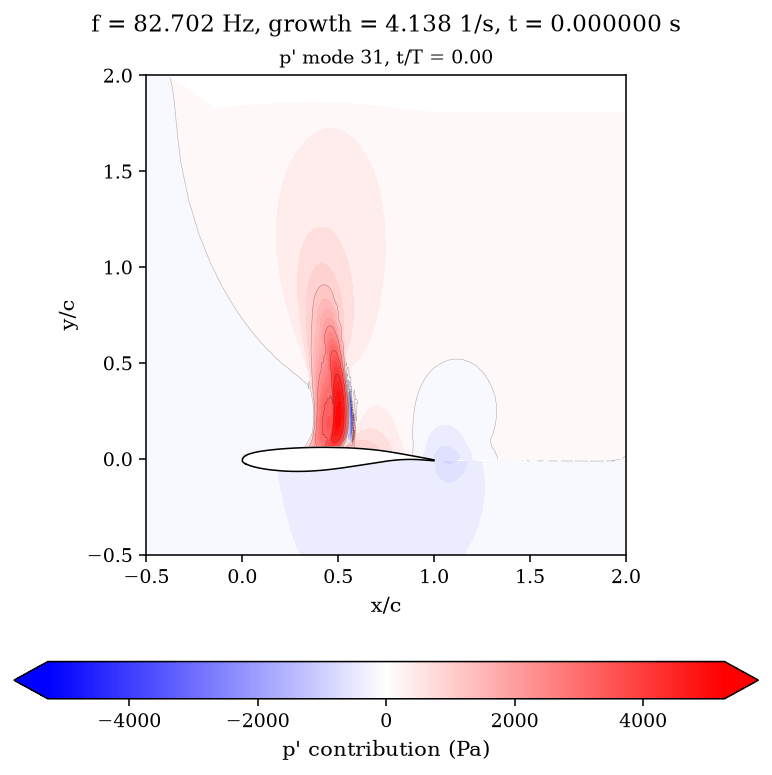

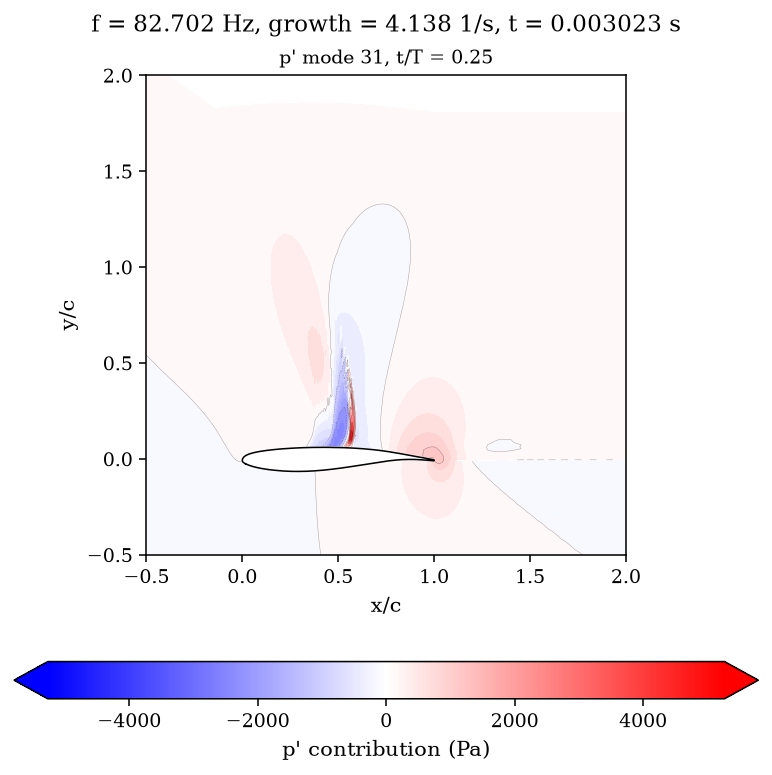

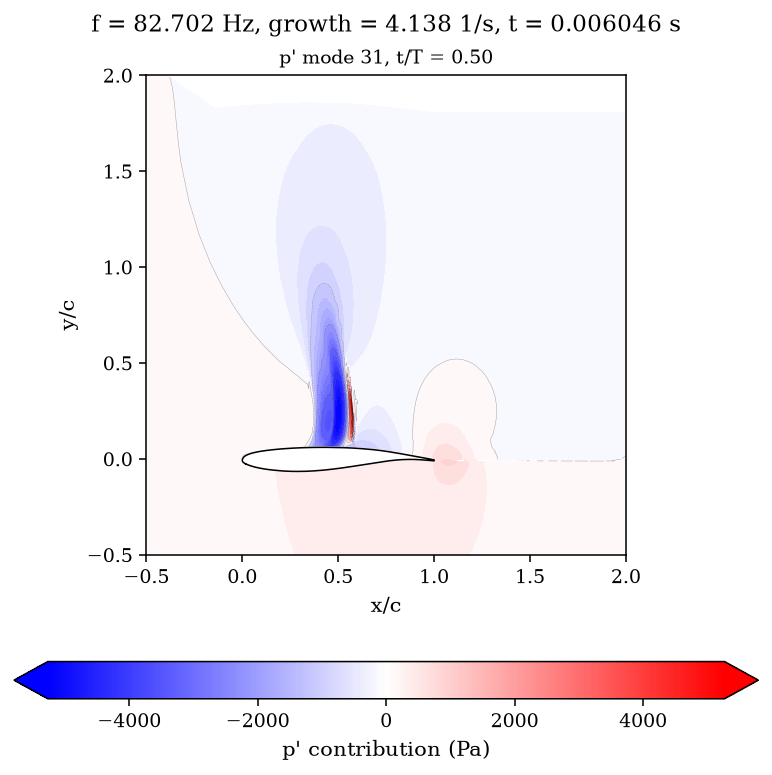

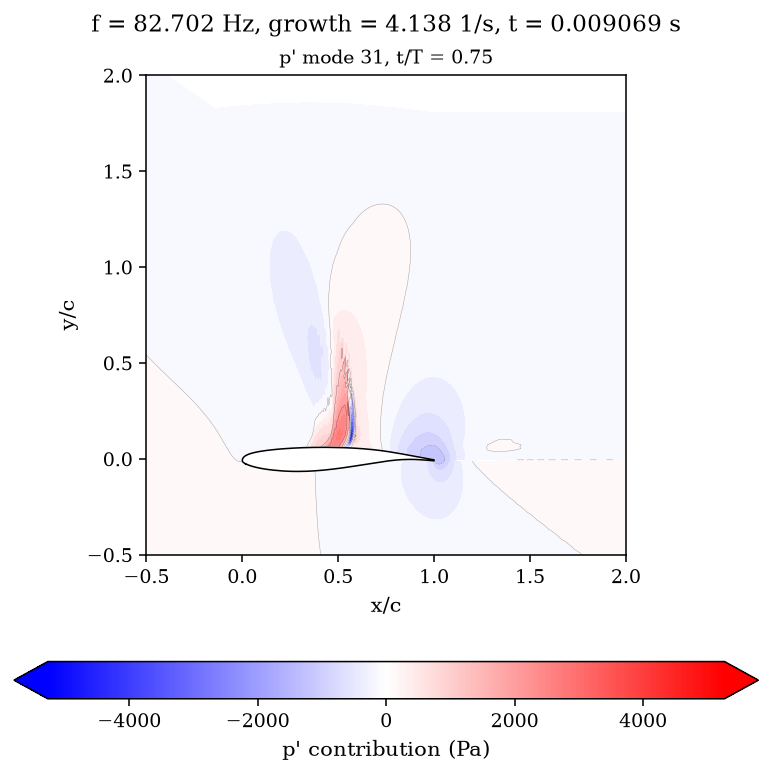

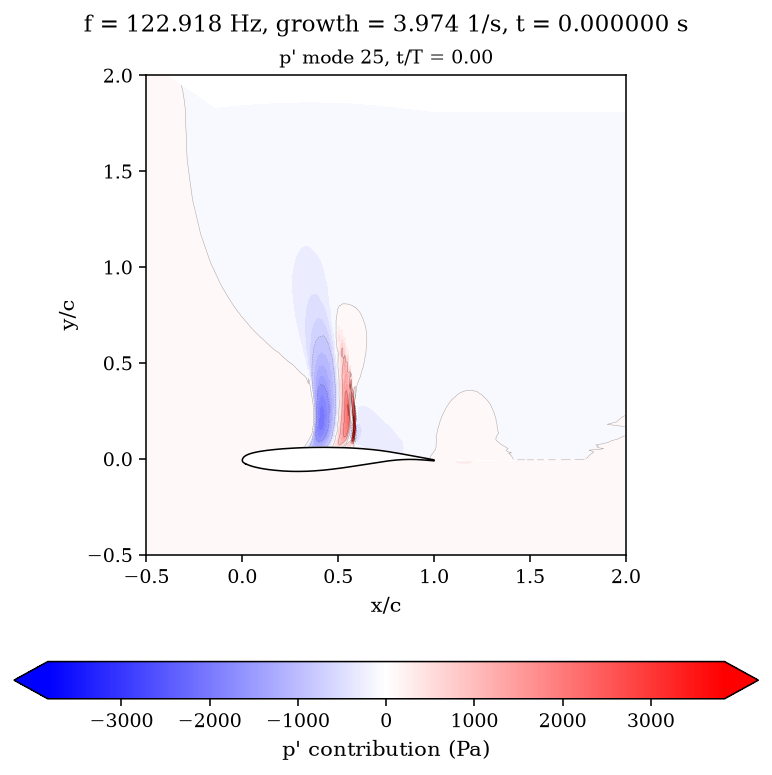

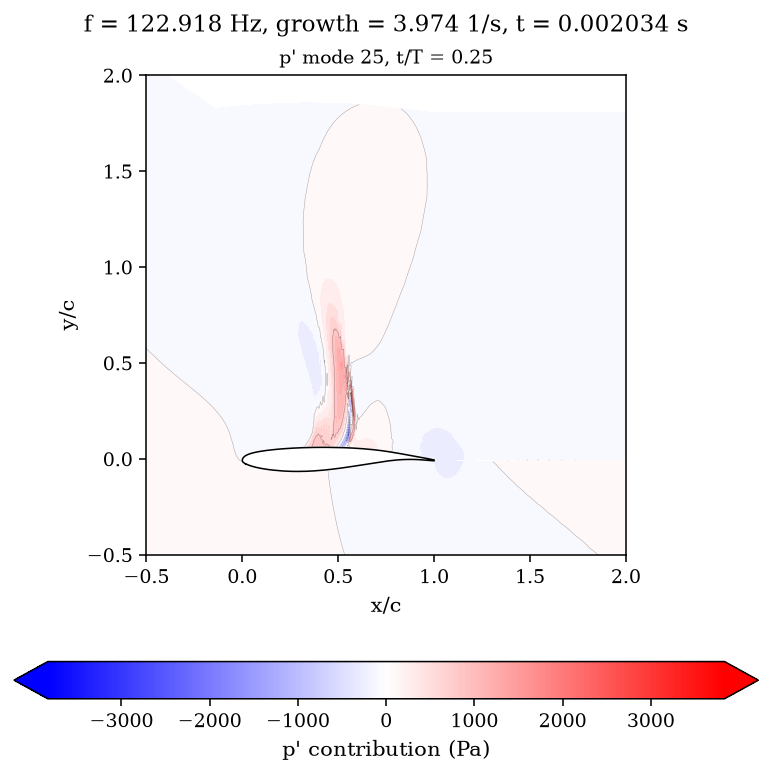

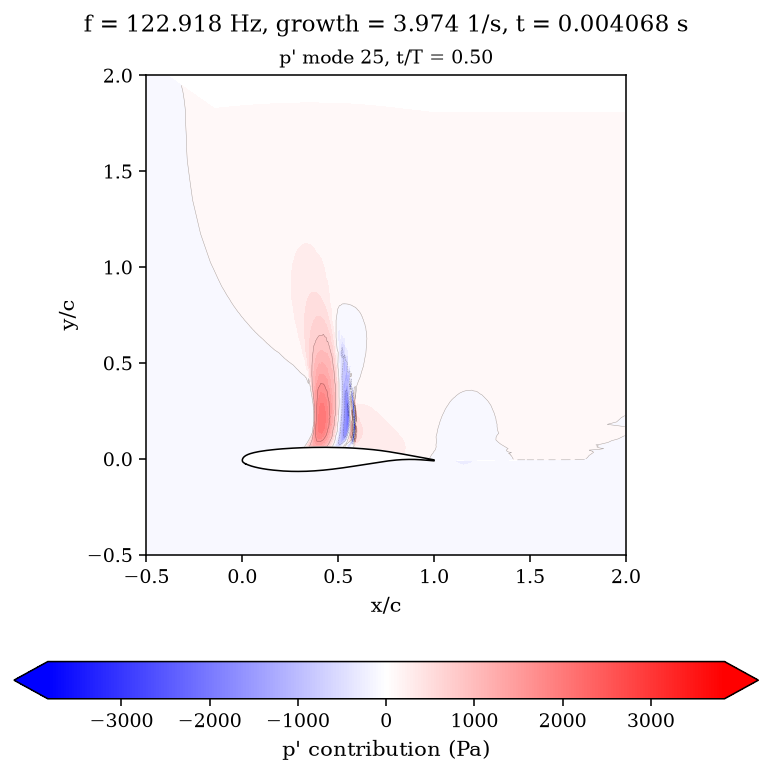

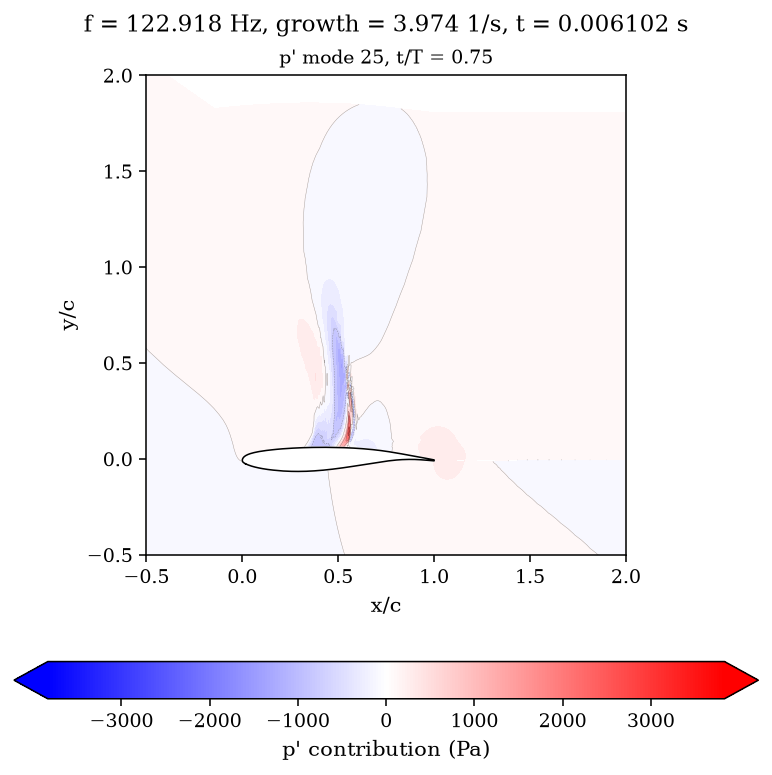

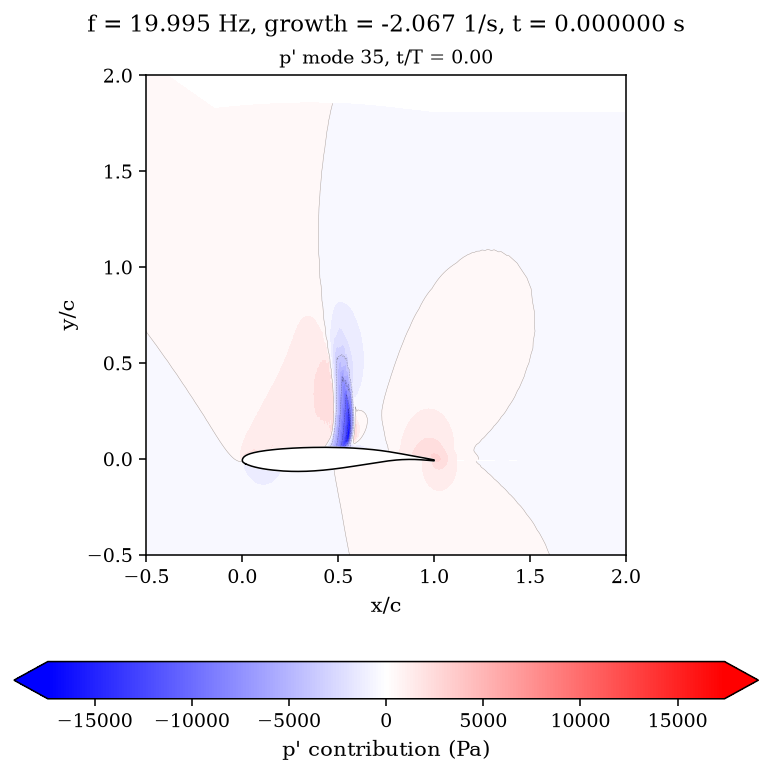

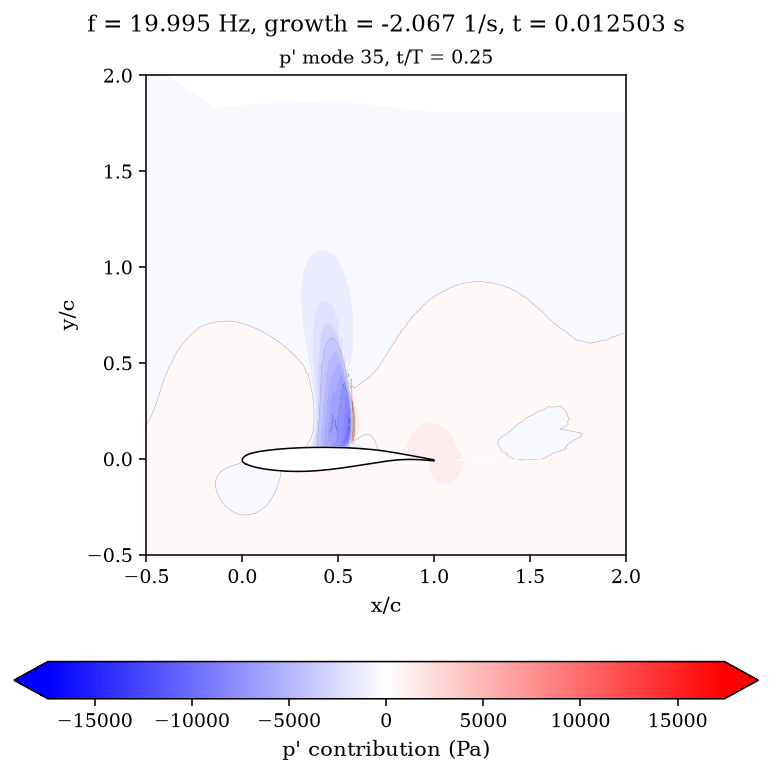

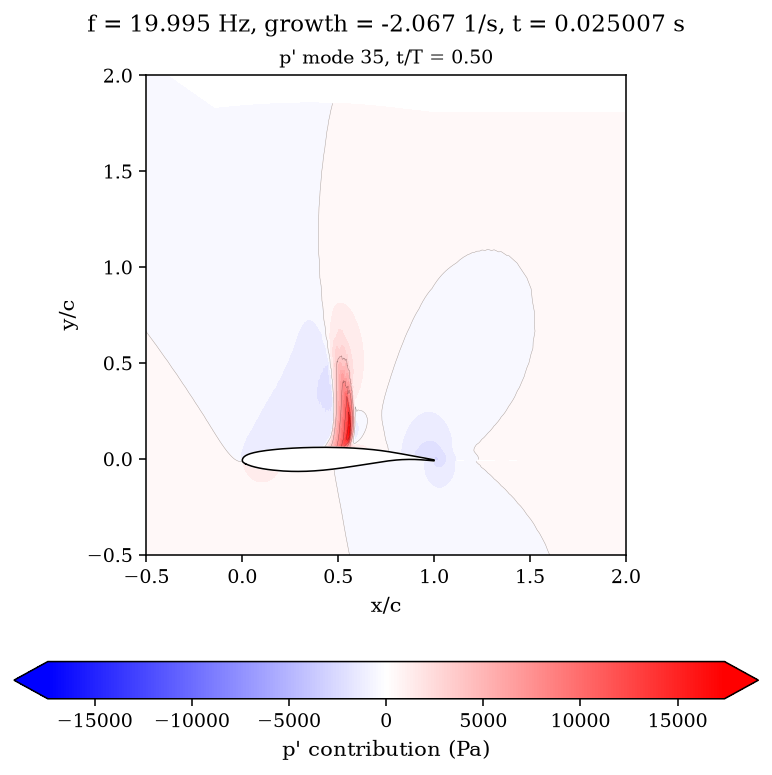

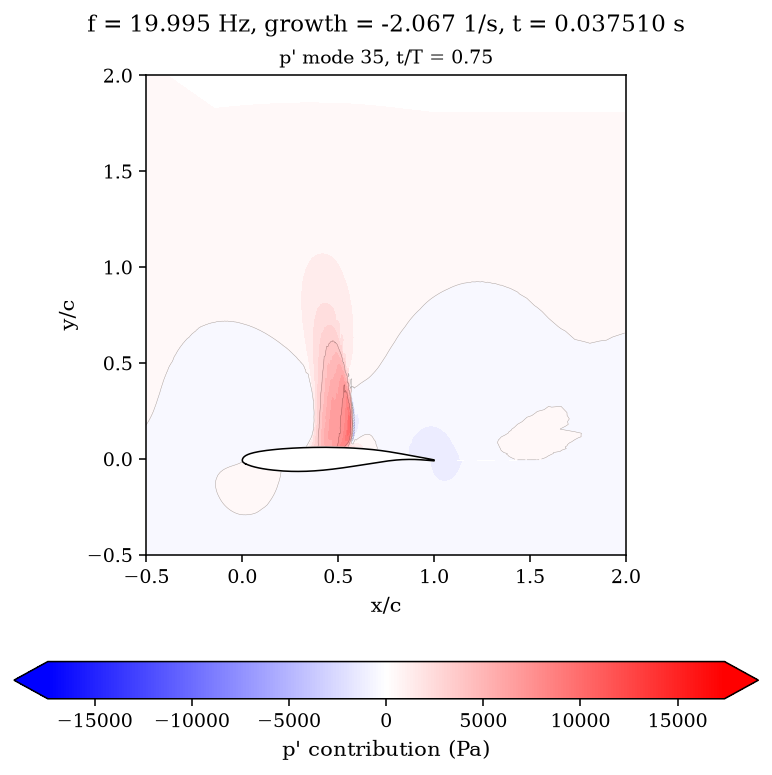

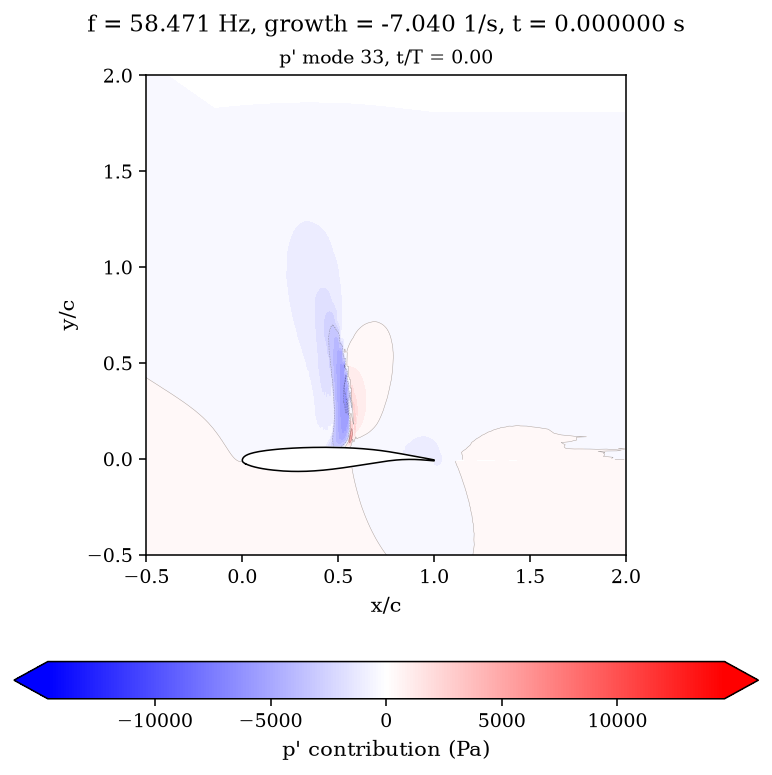

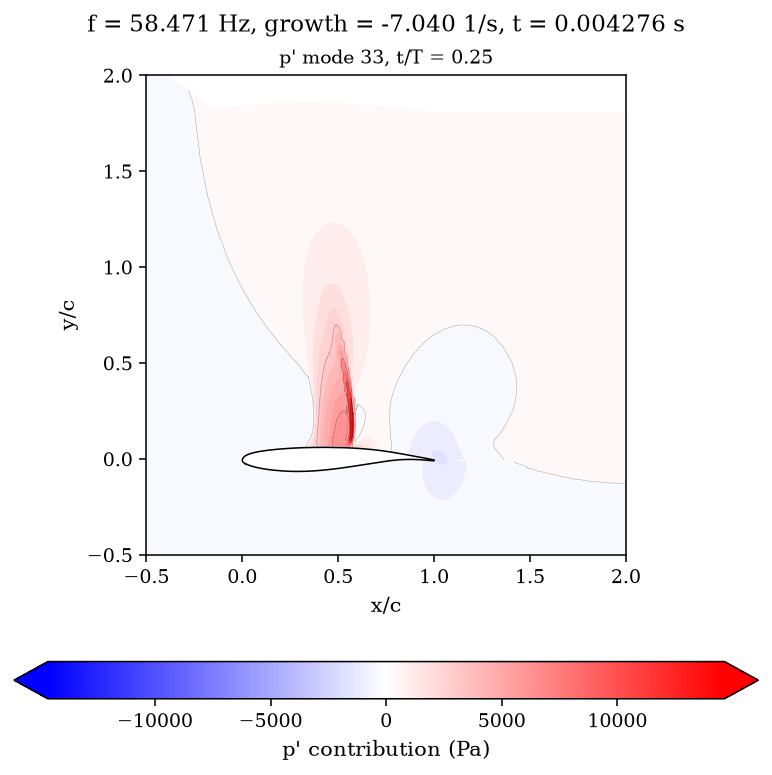

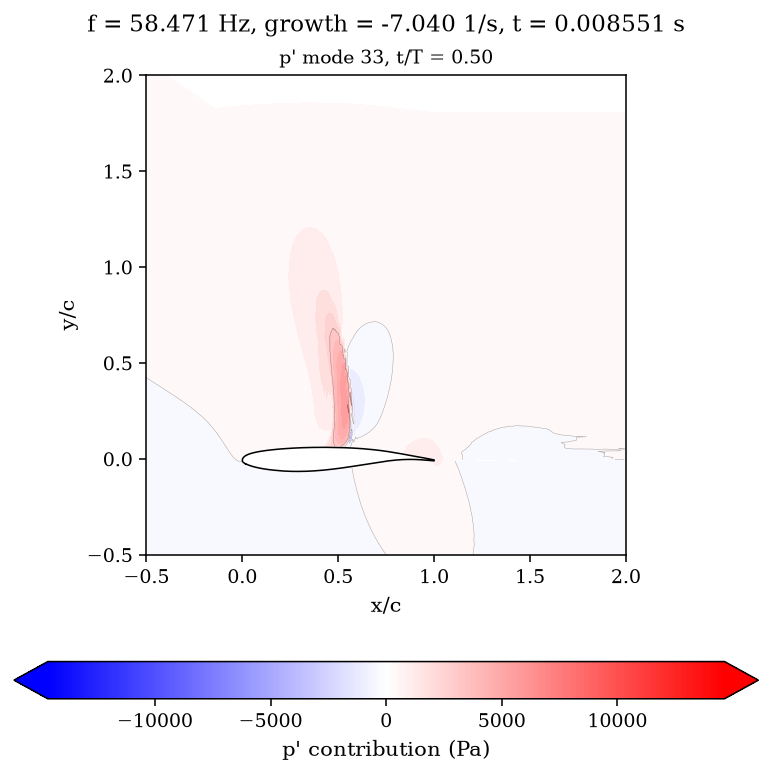

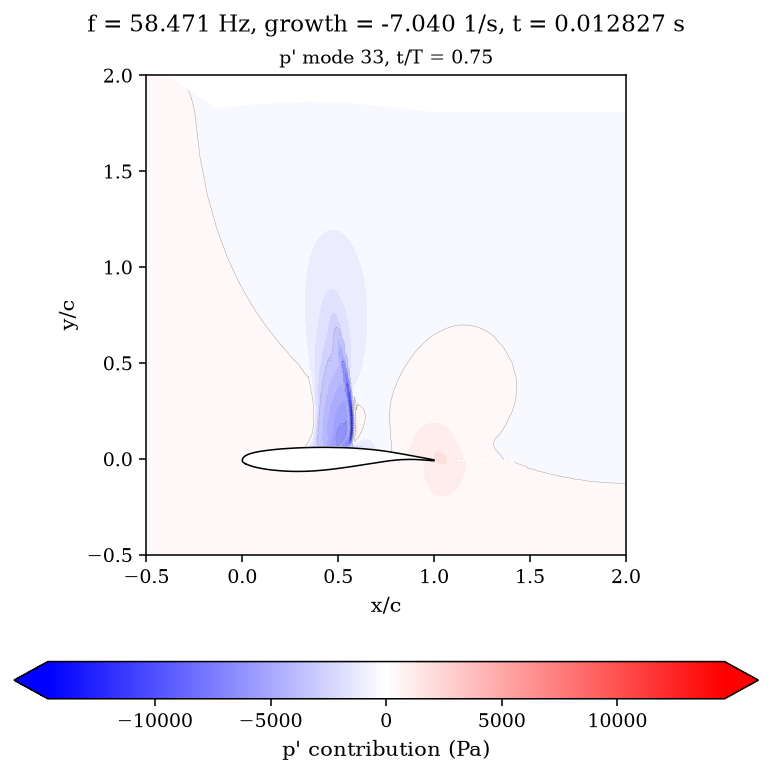

In [7]:
joint_x_blocks = [
    fluctuation[:-1, :, 0].T,
    fluctuation[:-1, :, 1].T,
    pressure_fluctuation[:-1].T,
]
joint_y_blocks = [
    fluctuation[1:, :, 0].T,
    fluctuation[1:, :, 1].T,
    pressure_fluctuation[1:].T,
]
component_scales = np.asarray([
    np.linalg.norm(block) / np.sqrt(block.size)
    for block in joint_x_blocks
])
joint_x = np.vstack([
    block / scale
    for block, scale in zip(joint_x_blocks, component_scales)
])
joint_y = np.vstack([
    block / scale
    for block, scale in zip(joint_y_blocks, component_scales)
])
U_joint, singular_values_joint, Vh_joint = np.linalg.svd(joint_x, full_matrices=False)
rank_joint = min(DMD_RANK, singular_values_joint.size)
Ujr = U_joint[:, :rank_joint]
Sjr = singular_values_joint[:rank_joint]
Vjr = Vh_joint.conj().T[:, :rank_joint]
A_tilde_joint = Ujr.conj().T @ joint_y @ Vjr / Sjr[None, :]
eigenvalues_joint, eigenvectors_joint = np.linalg.eig(A_tilde_joint)
modes_joint = joint_y @ Vjr / Sjr[None, :] @ eigenvectors_joint
omega_joint = np.log(eigenvalues_joint.astype(np.complex128)) / dt
amplitudes_joint = np.linalg.lstsq(modes_joint, joint_x[:, 0], rcond=None)[0]
frequency_joint = omega_joint.imag / (2.0 * np.pi)
growth_rate_joint = omega_joint.real
positive_joint = (frequency_joint > 0.0) & np.isfinite(frequency_joint) & np.isfinite(growth_rate_joint)
if not np.any(positive_joint):
    raise RuntimeError('no positive-frequency joint DMD mode was found')
N_MODE_PLOT = 4
N_FRAMES = 72
FPS = 25
growth_order = np.flatnonzero(positive_joint)
growth_order = growth_order[np.argsort(growth_rate_joint[growth_order])[::-1]]
selected_modes = growth_order[:N_MODE_PLOT]

def pressure_field(mode_index, sample_time):
    mode_values = modes_joint[2 * n_nodes:, mode_index] * component_scales[2]
    return 2.0 * np.real(
        mode_values * amplitudes_joint[mode_index] * np.exp(omega_joint[mode_index] * sample_time)
    )

def draw_pressure_axes(ax, values, levels):
    ax.tricontourf(tri, values[near], levels=levels, cmap='bwr', extend='both')
    ax.tricontour(tri, values[near], levels=levels[::4], colors='k', linewidths=0.25, alpha=0.35)
    ax.fill(body[:, 0], body[:, 1], color='white', zorder=3)
    ax.plot(body[:, 0], body[:, 1], color='k', linewidth=0.8, zorder=4)
    ax.set_xlim(*x_plot)
    ax.set_ylim(*y_plot)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('x/c')
    ax.set_ylabel('y/c')

mode_files = {}
for mode_index in selected_modes:
    mode_number = int(mode_index) + 1
    mode_frequency = float(frequency_joint[mode_index])
    mode_growth = float(growth_rate_joint[mode_index])
    mode_period = 1.0 / mode_frequency
    mode_phases = np.arange(4) * mode_period / 4.0
    mode_fields = np.column_stack([pressure_field(mode_index, phase_time) for phase_time in mode_phases])
    mode_span = float(np.max(np.abs(mode_fields)))
    mode_levels = np.linspace(-mode_span, mode_span, 41)
    mode_norm = Normalize(vmin=-mode_span, vmax=mode_span)
    phase_paths = []
    for phase_index, phase_time in enumerate(mode_phases):
        fig, ax = plt.subplots(figsize=(5.4, 5.4), layout='constrained')
        draw_pressure_axes(ax, mode_fields[:, phase_index], mode_levels)
        ax.set_title(f"p' mode {mode_number}, t/T = {phase_index / 4.0:.2f}")
        fig.colorbar(ScalarMappable(norm=mode_norm, cmap='bwr'), ax=ax, orientation='horizontal', pad=0.08, extend='both', label="p' contribution (Pa)")
        fig.suptitle(f'f = {mode_frequency:.3f} Hz, growth = {mode_growth:.3f} 1/s, t = {phase_time:.6f} s')
        phase_path = OUT_DIR / f'dmd_pressure_mode{mode_number:02d}_t{phase_index * 25:03d}.png'
        fig.savefig(phase_path)
        phase_paths.append(phase_path)
        plt.show()

    frame_times = np.arange(N_FRAMES) * mode_period / N_FRAMES
    frame_fields = np.column_stack([pressure_field(mode_index, frame_time) for frame_time in frame_times])
    anim_fig, anim_ax = plt.subplots(figsize=(5.2, 5.6), layout='constrained')
    anim_fig.colorbar(ScalarMappable(norm=mode_norm, cmap='bwr'), ax=anim_ax, orientation='horizontal', pad=0.08, extend='both', label="p' contribution (Pa)")

    def draw_pressure_frame(index):
        anim_ax.clear()
        draw_pressure_axes(anim_ax, frame_fields[:, index], mode_levels)
        anim_ax.set_title(
            f"p' mode {mode_number}, f = {mode_frequency:.2f} Hz, growth = {mode_growth:.2f} 1/s\n"
            f't/T = {index / N_FRAMES:.3f}'
        )
        return ()

    pressure_animation = animation.FuncAnimation(
        anim_fig, draw_pressure_frame, frames=N_FRAMES, interval=1000 // FPS
    )
    animation_path = OUT_DIR / f'dmd_pressure_mode{mode_number:02d}_animation.gif'
    pressure_animation.save(animation_path, writer=animation.PillowWriter(fps=FPS))
    plt.close(anim_fig)
    mode_files[mode_number] = (phase_paths, animation_path)

pressure_summary = pd.DataFrame({
    'mode': np.arange(1, rank_joint + 1),
    'eigenvalue_real': eigenvalues_joint.real,
    'eigenvalue_imag': eigenvalues_joint.imag,
    'frequency_hz': frequency_joint,
    'growth_rate_1_s': growth_rate_joint,
    'amplitude': np.abs(amplitudes_joint),
})
pressure_summary['amplitude_rank'] = pressure_summary['amplitude'].rank(method='first', ascending=False).astype(int)
pressure_summary['growth_rank'] = pressure_summary['growth_rate_1_s'].rank(method='first', ascending=False).astype(int)
pressure_summary['selected_for_plots'] = pressure_summary['mode'].isin([int(mode_index) + 1 for mode_index in selected_modes])
pressure_summary.to_csv(OUT_DIR / 'dmd_pressure_summary.csv', index=False)
first_mode = int(selected_modes[0])
np.savez_compressed(
    OUT_DIR / 'dmd_pressure_results.npz',
    eigenvalues=eigenvalues_joint,
    omega=omega_joint,
    modes=modes_joint[2 * n_nodes:] * component_scales[2],
    amplitudes=amplitudes_joint,
    singular_values=singular_values_joint,
    selected_modes=np.asarray(selected_modes, dtype=int),
    dominant_mode=np.array(first_mode),
    phase_times=np.arange(4) * (1.0 / float(frequency_joint[first_mode])) / 4.0,
    phase_fields=np.column_stack([
        pressure_field(first_mode, phase_time)
        for phase_time in np.arange(4) * (1.0 / float(frequency_joint[first_mode])) / 4.0
    ]),
)
print(pressure_summary[pressure_summary['selected_for_plots']][
    ['mode', 'frequency_hz', 'growth_rate_1_s', 'amplitude', 'amplitude_rank', 'growth_rank']
].to_string(index=False))
for mode_number, (phase_paths, animation_path) in mode_files.items():
    print(f'--- mode {mode_number} ---')
    for phase_path in phase_paths:
        print(phase_path)
    print(animation_path)
print(OUT_DIR / 'dmd_pressure_summary.csv')
